# Лабораторная работа № 2
## Аугментация данных и устойчивость
Цель работы - посмотреть, **как шум, реверберация и изменение скорости влияют на распознавание речи** моделью Whisper `tiny.en`

Для эксперимента используются **пять фраз одного диктора из LibriSpeech dev-clean** и семь условий, включая исходную запись. Получается 35 аудиофайлов. Качество текста сравню по WER и CER, а скорость обработки - по RTF

**Аугментация** - это создание изменённого варианта уже имеющейся записи. Например, можно взять одну фразу и добавить к ней шум, как будто человек говорит рядом с вентилятором. При умеренном искажении ожидаемый текст остаётся тем же, а условия для распознавания меняются

**Устойчивость модели**: насколько сильно портится результат после такого изменения

Для генерации шумовых вариантов использую **`SEED = 42`**.
В исходном манифесте остаётся `seed = 17`, но при создании аугментаций ниже явно передаю 42


Какие именно аугментации проверяются:

| Условие | Что происходит | Ожидаемый эффект |
|---|---|---|
| `clean` | Исходная речь | Базовый результат для сравнения |
| `noise_20db` | Добавлен слабый белый шум | Небольшое ухудшение или отсутствие изменений |
| `noise_10db` | Добавлен более сильный шум | Возможны дополнительные ошибки |
| `noise_0db` | Средние мощности речи и шума равны | Вероятно, заметное ухудшение |
| `reverb_room_a` | Добавлены синтетические отражения | Звуки растягиваются во времени и накладываются друг на друга |
| `speed_0.9x` | Речь замедлена | Длительность увеличивается, высота голоса понижается |
| `speed_1.1x` | Речь ускорена | Длительность сокращается, высота голоса повышается |

**SNR** - отношение мощности сигнала к мощности шума:

$$SNR_{dB} = 10\log_{10}\frac{P_{\text{речи}}}{P_{\text{шума}}}$$

При 20 dB мощность речи в 100 раз больше мощности добавленного шума, при 10 dB - в 10 раз, а при 0 dB они равны.\
Т.е. **чем меньше SNR, тем сильнее шум относительно речи**

Для себя это представляю как разговор на фоне работающего прибора: чем сильнее фон относительно голоса, тем сложнее разобрать тихие звуки.\
в коде используется белый шум


Предоставленные файлы:

| Файл | Назначение |
|---|---|
| `make_lab02_subset.py` | Проверяет исходные записи и манифест |
| `augment_audio.py` | Создаёт шум, реверберацию и изменение скорости |
| `plot_augmentation_features.py` | Строит waveform, log-Mel и пример SpecAugment |
| `run_local_asr.py` | Распознаёт аудио через Whisper |
| `score_robustness.py` | Вычисляет WER, CER, RTF и общие результаты |
| `run_lab_02.py` | Последовательно запускает этапы лабораторной |

Манифест - это список записей: в нём для каждого ID указаны путь к WAV, правильный текст и длительность.\
По нему программа понимает, **какой текст с каким аудио сравнивать**.


# 0. Подготовка

## 1. Окружение

В терминале :
```powershell
conda create -n ASR_lr2_ITMO python=3.11 -y
conda activate ASR_lr2_ITMO

conda env config vars set PYTHONNOUSERSITE=1
conda deactivate
conda activate ASR_lr2_ITMO

conda install -c conda-forge uv -y
uv --version

uv pip install -r requirements.txt
python -c "import numpy, scipy, soundfile, librosa, matplotlib, faster_whisper, av; print('OK')"

python -m ipykernel install --user --name ASR_lr2_ITMO --display-name "ASR_lr2_ITMO"
```

### Импорт

In [1]:
from pathlib import Path
import sys
import subprocess
import pandas as pd
import soundfile as sf
from importlib.util import find_spec

from IPython.display import display, Image, Audio

from importlib.metadata import version, PackageNotFoundError
from packaging.requirements import Requirement

ROOT = Path.cwd()
requirements_path = ROOT / "requirements.txt"

ASR_LIBRARIES_READY = True

with open(requirements_path, encoding="utf-8") as file:
    for line in file:
        line = line.strip()

        if not line or line.startswith("#"):
            continue

        req = Requirement(line)

        try:
            v = version(req.name)
            ok = v in req.specifier
        except PackageNotFoundError:
            v = "не установлена"
            ok = False

        print(f"{req.name:<16}\t{v:<8}\t{'+' if ok else '-'}")

        if req.name in ["faster-whisper", "av"] and not ok:
            ASR_LIBRARIES_READY = False

print(f"\nASR_LIBRARIES_READY:\t{ASR_LIBRARIES_READY}")

numpy           	2.4.6   	+
scipy           	1.17.1  	+
soundfile       	0.14.0  	+
librosa         	0.11.0  	+
matplotlib      	3.11.2  	+
faster-whisper  	1.2.1   	+
av              	18.1.0  	+
jupyter         	1.1.1   	+
nbformat        	5.11.1  	+
pytest          	9.1.1   	+
pandas          	3.0.6   	+

ASR_LIBRARIES_READY:	True


In [2]:
SEED = 42

SCRIPTS = ROOT / "scripts"
DATA = ROOT / "data"
WAV = DATA / "wav"
OUT = ROOT / "outputs"
AUG = OUT / "augmented"
FIG = OUT / "figures"
RESULTS = OUT / "results"

for folder in [SCRIPTS, DATA, WAV, OUT, AUG, FIG, RESULTS]:
    folder.mkdir(parents=True, exist_ok=True)
    print("Папка:	", folder)

CONDITIONS = [
    "clean", 
    "noise_20db", 
    "noise_10db", 
    "noise_0db",
    "reverb_room_a", 
    "speed_0.9x", 
    "speed_1.1x"
]

ALLOW_MODEL_DOWNLOAD = True
RUN_ASR = True

print("SEED:	", SEED)

Папка:	 d:\МАГА\2 курс\ASR\lab_02_ru\scripts
Папка:	 d:\МАГА\2 курс\ASR\lab_02_ru\data
Папка:	 d:\МАГА\2 курс\ASR\lab_02_ru\data\wav
Папка:	 d:\МАГА\2 курс\ASR\lab_02_ru\outputs
Папка:	 d:\МАГА\2 курс\ASR\lab_02_ru\outputs\augmented
Папка:	 d:\МАГА\2 курс\ASR\lab_02_ru\outputs\figures
Папка:	 d:\МАГА\2 курс\ASR\lab_02_ru\outputs\results
SEED:	 42


## 2. Скрипты из задания

Проверяю, что файлы находятся в `scripts/`

**Код этих скриптов предоставлен в задании.** В блокноте я задаю `SEED = 42` и передаю его при запуске аугментаций


In [3]:
script_names = [
    "make_lab02_subset.py",
    "augment_audio.py",
    "plot_augmentation_features.py",
    "run_local_asr.py",
    "score_robustness.py",
    "run_lab_02.py"
]

for name in script_names:
    path = SCRIPTS / name

    status = "файл существует" if path.exists() else "файл не найден"
    print(f"{name:<32}\t{status}")

make_lab02_subset.py            	файл существует
augment_audio.py                	файл существует
plot_augmentation_features.py   	файл существует
run_local_asr.py                	файл существует
score_robustness.py             	файл существует
run_lab_02.py                   	файл существует


## 3. Подготавливаю исходные записи

В лабораторной используются пять записей из `LibriSpeech dev-clean`. Ниже читаю **уже подготовленный** `data/manifest.jsonl`, получаю ID, правильные тексты и проверяю наличие WAV


In [4]:
manifest_path = DATA / "manifest.jsonl"

MANIFEST = pd.DataFrame()
IDS = []
REFS = {}
DATA_READY = False

if manifest_path.exists():
    MANIFEST = pd.read_json(manifest_path, lines=True)

    IDS = MANIFEST["item_id"].tolist()
    REFS = dict(zip(MANIFEST["item_id"], MANIFEST["reference_raw"]))

    DATA_READY = len(MANIFEST) == 5

    for path in MANIFEST["audio_path"]:
        wav_file = (ROOT / path).resolve()

        if wav_file.exists():
            print(wav_file, "\tнайден")
        else:
            print(wav_file, "\tне найден")
            DATA_READY = False

else:
    print("Манифест не найден:\t", manifest_path.resolve())

D:\МАГА\2 курс\ASR\lab_02_ru\data\wav\1272-128104-0000.wav 	найден
D:\МАГА\2 курс\ASR\lab_02_ru\data\wav\1272-128104-0001.wav 	найден
D:\МАГА\2 курс\ASR\lab_02_ru\data\wav\1272-128104-0003.wav 	найден
D:\МАГА\2 курс\ASR\lab_02_ru\data\wav\1272-128104-0006.wav 	найден
D:\МАГА\2 курс\ASR\lab_02_ru\data\wav\1272-128104-0007.wav 	найден


In [5]:
display(MANIFEST.style.format({"duration_seconds": "{:.3f}"}))

,item_id,audio_path,reference_raw,reference_normalized,duration_seconds,source_utterance_id,source_split,seed
0,1272-128104-0000,data/wav/1272-128104-0000.wav,MISTER QUILTER IS THE APOSTLE OF THE MIDDLE CLASSES AND WE ARE GLAD TO WELCOME HIS GOSPEL,mister quilter is the apostle of the middle classes and we are glad to welcome his gospel,5.855,1272-128104-0000,LibriSpeech dev-clean,17
1,1272-128104-0001,data/wav/1272-128104-0001.wav,NOR IS MISTER QUILTER'S MANNER LESS INTERESTING THAN HIS MATTER,nor is mister quilter's manner less interesting than his matter,4.815,1272-128104-0001,LibriSpeech dev-clean,17
2,1272-128104-0003,data/wav/1272-128104-0003.wav,HE HAS GRAVE DOUBTS WHETHER SIR FREDERICK LEIGHTON'S WORK IS REALLY GREEK AFTER ALL AND CAN DISCOVER IN IT BUT LITTLE OF ROCKY ITHACA,he has grave doubts whether sir frederick leighton's work is really greek after all and can discover in it but little of rocky ithaca,9.900,1272-128104-0003,LibriSpeech dev-clean,17
3,1272-128104-0006,data/wav/1272-128104-0006.wav,ON THE GENERAL PRINCIPLES OF ART MISTER QUILTER WRITES WITH EQUAL LUCIDITY,on the general principles of art mister quilter writes with equal lucidity,5.640,1272-128104-0006,LibriSpeech dev-clean,17
4,1272-128104-0007,data/wav/1272-128104-0007.wav,PAINTING HE TELLS US IS OF A DIFFERENT QUALITY TO MATHEMATICS AND FINISH IN ART IS ADDING MORE FACT,painting he tells us is of a different quality to mathematics and finish in art is adding more fact,9.240,1272-128104-0007,LibriSpeech dev-clean,17


## 4. Проверяю данные

Запускаю `make_lab02_subset.py`: он проверяет поля манифеста, наличие аудио, **16 кГц, один канал** и соответствие указанной длительности реальному WAV

16 кГц означает 16 000 отсчётов в секунду. Например, в пятисекундной записи будет около 80 000 отсчётов. Это частота измерения сигнала, а не громкость голоса


In [6]:
# Одна небольшая функция, чтобы не писать subprocess.run много раз
def run_script(name, *options):
    command = [sys.executable, str(SCRIPTS / name)]
    for option in options:
        command.append(str(option))
    print("Запускаю:	", name)
    subprocess.run(command, cwd=ROOT, check=True)

In [7]:
if DATA_READY and manifest_path.exists():
    run_script("make_lab02_subset.py")
    print("Проверка исходных данных завершилась.")
else:
    print("Проверка данных пропущена, потому что не хватает файлов.")

Запускаю:	 make_lab02_subset.py
Проверка исходных данных завершилась.


## 5. Создаю аугментации

Для каждой из пяти фраз создаю семь условий: `clean`, три уровня шума, `reverb_room_a`, `speed_0.9x` и `speed_1.1x`.\
В сумме ожидаю **35 WAV** и описание условий в `conditions.jsonl`

Сравнение получается парным: у каждой фразы есть исходный и изменённые варианты. Текст и диктор остаются теми же => проще связать разницу с выбранным искажением

In [8]:
AUG_READY = False

if DATA_READY:
    run_script("augment_audio.py", "--manifest", manifest_path,
               "--out-dir", AUG, "--seed", SEED)

    AUG_READY = True
    for item_id in IDS:
        for condition in CONDITIONS:
            wav_file = AUG / (item_id + "__" + condition + ".wav")
            if not wav_file.exists():
                AUG_READY = False
                print("Нет файла:	", wav_file)

    if not (AUG / "conditions.jsonl").exists():
        AUG_READY = False
        print("Не найден conditions.jsonl")

    if AUG_READY:
        print("Подготовлено 35 аудиофайлов и conditions.jsonl")
else:
    print("Сначала нужны исходные WAV.")

Запускаю:	 augment_audio.py
Подготовлено 35 аудиофайлов и conditions.jsonl


## 6. Строю графики

Сначала сравниваю оригинал с `noise_10db`, затем отдельно с `reverb_room_a` и `noise_0db`. Скрипт строит **волновую форму и log-Mel-спектрограмму**

- waveform показывает, как амплитуда меняется во времени
- log-Mel показывает, в каких частотных областях находится энергия в каждый момент времени

Как и в первой лабораторной, одного графика недостаточно: похожая волновая форма ещё не означает одинаковый частотный состав !

In [9]:
FIG_READY = False

if AUG_READY:
    clean_file = WAV / (IDS[0] + ".wav")

    # Сначала два основных графика
    run_script("plot_augmentation_features.py",
               "--clean", clean_file,
               "--augmented", AUG / (IDS[0] + "__noise_10db.wav"),
               "--out-dir", FIG)

    # Теперь сравнения, которые нужны для разбора результатов
    for condition in ["reverb_room_a", "noise_0db"]:
        folder = FIG / condition
        run_script("plot_augmentation_features.py",
                   "--clean", clean_file,
                   "--augmented", AUG / (IDS[0] + "__" + condition + ".wav"),
                   "--out-dir", folder)
        print("Папка графиков:	", folder)

    # Простая проверка наличия изображений после запусков
    FIG_READY = True
    for path in [
        FIG / "clean_vs_augmented.png",
        FIG / "specaugment_feature_only.png",
        FIG / "reverb_room_a" / "clean_vs_augmented.png",
        FIG / "noise_0db" / "clean_vs_augmented.png"
    ]:
        if path.exists():
            print("Рисунок найден:	", path)
        else:
            print("Нет рисунка:	", path)
            FIG_READY = False
else:
    print("Сначала нужно создать аугментированные WAV")

Запускаю:	 plot_augmentation_features.py
Запускаю:	 plot_augmentation_features.py
Папка графиков:	 d:\МАГА\2 курс\ASR\lab_02_ru\outputs\figures\reverb_room_a
Запускаю:	 plot_augmentation_features.py
Папка графиков:	 d:\МАГА\2 курс\ASR\lab_02_ru\outputs\figures\noise_0db
Рисунок найден:	 d:\МАГА\2 курс\ASR\lab_02_ru\outputs\figures\clean_vs_augmented.png
Рисунок найден:	 d:\МАГА\2 курс\ASR\lab_02_ru\outputs\figures\specaugment_feature_only.png
Рисунок найден:	 d:\МАГА\2 курс\ASR\lab_02_ru\outputs\figures\reverb_room_a\clean_vs_augmented.png
Рисунок найден:	 d:\МАГА\2 курс\ASR\lab_02_ru\outputs\figures\noise_0db\clean_vs_augmented.png


## 7. Проверочный запуск без распознавания

Выполняю `run_lab_02.py --skip-asr`. Скрипт проверяет данные, заново создаёт аугментации и основные графики

In [10]:
SKIP_ASR_OK = False

if FIG_READY:
    run_script("run_lab_02.py", "--skip-asr", "--seed", SEED)

    # Смотрим, на месте ли результаты этого этапа.
    if (AUG / "conditions.jsonl").exists() and (FIG / "clean_vs_augmented.png").exists():
        SKIP_ASR_OK = True
        print("Пробный запуск без ASR выполнен.")
    else:
        print("После запуска не все файлы найдены.")
else:
    print("Пропускаю этот запуск, так как графики ещё не готовы.")

Запускаю:	 run_lab_02.py
Пробный запуск без ASR выполнен.


## 8. Полный запуск Whisper

Теперь выполняю `run_lab_02.py` с распознаванием. Используются **Whisper `tiny.en`, CPU, `int8`, английский язык, `beam_size=1`, `vad_filter=False`**. `int8` задаёт способ хранения и вычисления части чисел модели, а `beam_size=1` означает, что декодер не ведёт расширенный поиск нескольких альтернативных последовательностей текста.

Модель получает аудио и строит гипотезу - предполагаемый текст. Затем скрипт оценки сравнивает её с эталоном. Эталон нужен для подсчёта ошибок

Если модели ещё нет в кэше, нужен `--allow-model-download`


In [11]:
ASR_READY = False
ASR_RUN_OK = False

if SKIP_ASR_OK and RUN_ASR and ASR_LIBRARIES_READY:
    try:
        if ALLOW_MODEL_DOWNLOAD:
            run_script("run_lab_02.py", "--seed", SEED, "--allow-model-download")
        else:
            run_script("run_lab_02.py", "--seed", SEED)

        ASR_RUN_OK = True
        print("Полный запуск скрипта завершился.")
    except Exception as error:
        print("При распознавании произошла ошибка:", error)
else:
    print("Полный запуск пока не выполнен: нет данных или нужных библиотек.")

# Файлы проверяем отдельно от сообщения о запуске.
raw_path = OUT / "raw_asr.jsonl"
per_item_path = RESULTS / "per_item_results.csv"
aggregate_path = RESULTS / "aggregate_results.csv"

for path in [raw_path, per_item_path, aggregate_path]:
    if path.exists():
        print("Файл существует:	", path)
    else:
        print("Файла пока нет:	", path)

Запускаю:	 run_lab_02.py
Полный запуск скрипта завершился.
Файл существует:	 d:\МАГА\2 курс\ASR\lab_02_ru\outputs\raw_asr.jsonl
Файл существует:	 d:\МАГА\2 курс\ASR\lab_02_ru\outputs\results\per_item_results.csv
Файл существует:	 d:\МАГА\2 курс\ASR\lab_02_ru\outputs\results\aggregate_results.csv


### Отдельно проверяю расчёт метрик

`score_robustness.py` уже вызывается внутри основного скрипта. Запускаю его ещё раз отдельно, чтобы проверить заключительный этап и получить оба CSV по сохранённым гипотезам

Перед сравнением скрипт переводит текст в нижний регистр, убирает большинство знаков пунктуации и лишние пробелы. Апострофы сохраняет. Т.е. `Hello!` и `hello` после такой обработки совпадут

Но **`mister` и `mr` не становятся одним словом**: нормализатор не раскрывает сокращения и не проверяет смысл


In [12]:
if raw_path.exists() and ASR_RUN_OK:
    run_script("score_robustness.py", "--input", raw_path, "--out-dir", RESULTS)

item_rows = pd.DataFrame()
agg_rows = pd.DataFrame()

if per_item_path.exists() and aggregate_path.exists() and ASR_RUN_OK:
    item_rows = pd.read_csv(per_item_path)
    agg_rows = pd.read_csv(aggregate_path)

    ASR_READY = True

    print("Результатов по аудио:\t", len(item_rows))
    print("Средних результатов:\t", len(agg_rows))
else:
    print("Таблицы результатов пока не получены.")

Запускаю:	 score_robustness.py
Результатов по аудио:	 35
Средних результатов:	 7


## 9. Основные метрики

Для оценки использую WER, CER и RTF. Первые две метрики отвечают за совпадение текста с эталоном, третья - за скорость обработки


### WER (Word Error Rate)

**WER** считает ошибки на уровне слов:

$$WER = \frac{S+D+I}{N_{\text{слов}}}$$

где $S$ - замены, $D$ - удаления, $I$ - вставки, а $N_{\text{слов}}$ - число слов в эталоне. Для расчёта тексты выравниваются так, чтобы общее число этих операций было минимальным

Например, эталон `the cat sleeps`, а модель написала `the dog sleeps`: одна замена на три слова => **WER = 1/3 = 0.333**. Если вместо этого появится лишнее слово `the small cat sleeps`, будет одна вставка и такой же WER

Чем меньше WER, тем лучше совпадает текст. Ноль означает отсутствие ошибок после нормализации. **WER может быть больше 1**, если модель добавила много лишних слов; это не вероятность, ограниченная 100%


### CER (Character Error Rate)

**CER** использует тот же принцип, но сравнивает символы:

$$CER = \frac{S_c+D_c+I_c}{N_{\text{символов}}}$$

Например, для одного слова `cat` -> `cats` WER будет 1, а CER = 1/3: всё слово для WER уже неправильное, но три исходные буквы сохранились

WER и CER полезно смотреть вместе: они описывают ошибки с разной подробностью. При этом CER не обязан всегда быть меньше WER, а ни одна из метрик напрямую не измеряет сохранение смысла фразы


### RTF (Real-Time Factor)

**RTF** - отношение времени распознавания к длительности аудио:

$$RTF = \frac{t_{\text{распознавания}}}{t_{\text{аудио}}}$$

Если запись длится 10 секунд, а обработка заняла 0.5 секунды, RTF = 0.05. Значение меньше 1 означает обработку быстрее реального времени; больше 1 - медленнее.

**Маленький RTF не гарантирует правильного текста.** Модель может быстро выдать ошибочную фразу



### Общие результаты

`mean_wer` и `mean_cer` - обычные средние по пяти фразам. Каждая фраза имеет одинаковый вес, хотя длины у них разные\
`mean_rtf` считается иначе: **суммарное время распознавания / суммарная длительность аудио**

In [13]:
if ASR_READY:
    columns = ["mean_wer", "mean_cer", "mean_rtf"]

    display(agg_rows[["condition"] + columns].style.format("{:.4f}", subset=columns))
else:
    print("Пока нет CSV с реальными результатами распознавания.")

,condition,mean_wer,mean_cer,mean_rtf
0,clean,0.0840,0.0500,0.0374
1,noise_0db,0.7000,0.3902,0.0815
2,noise_10db,0.1823,0.1001,0.0377
3,noise_20db,0.1206,0.0730,0.0378
4,reverb_room_a,0.1206,0.0608,0.0365
5,speed_0.9x,0.0840,0.0480,0.0330
6,speed_1.1x,0.0673,0.0446,0.0413


# Ответы на вопросы


## Задание 1. Выберите пару аугментаций, и проанализируйте, как они влияют на сигнал (поможет построить графики, подобные clean_vs_augmented.png). Какие два видимые изменения вы наблюдаете в волновой форме и/или log-Mel представлении?


Выбрал **шум `noise_10db`** и **реверберацию `reverb_room_a`** для одной и той же фразы

Сначала оригинал и шум 10 dB


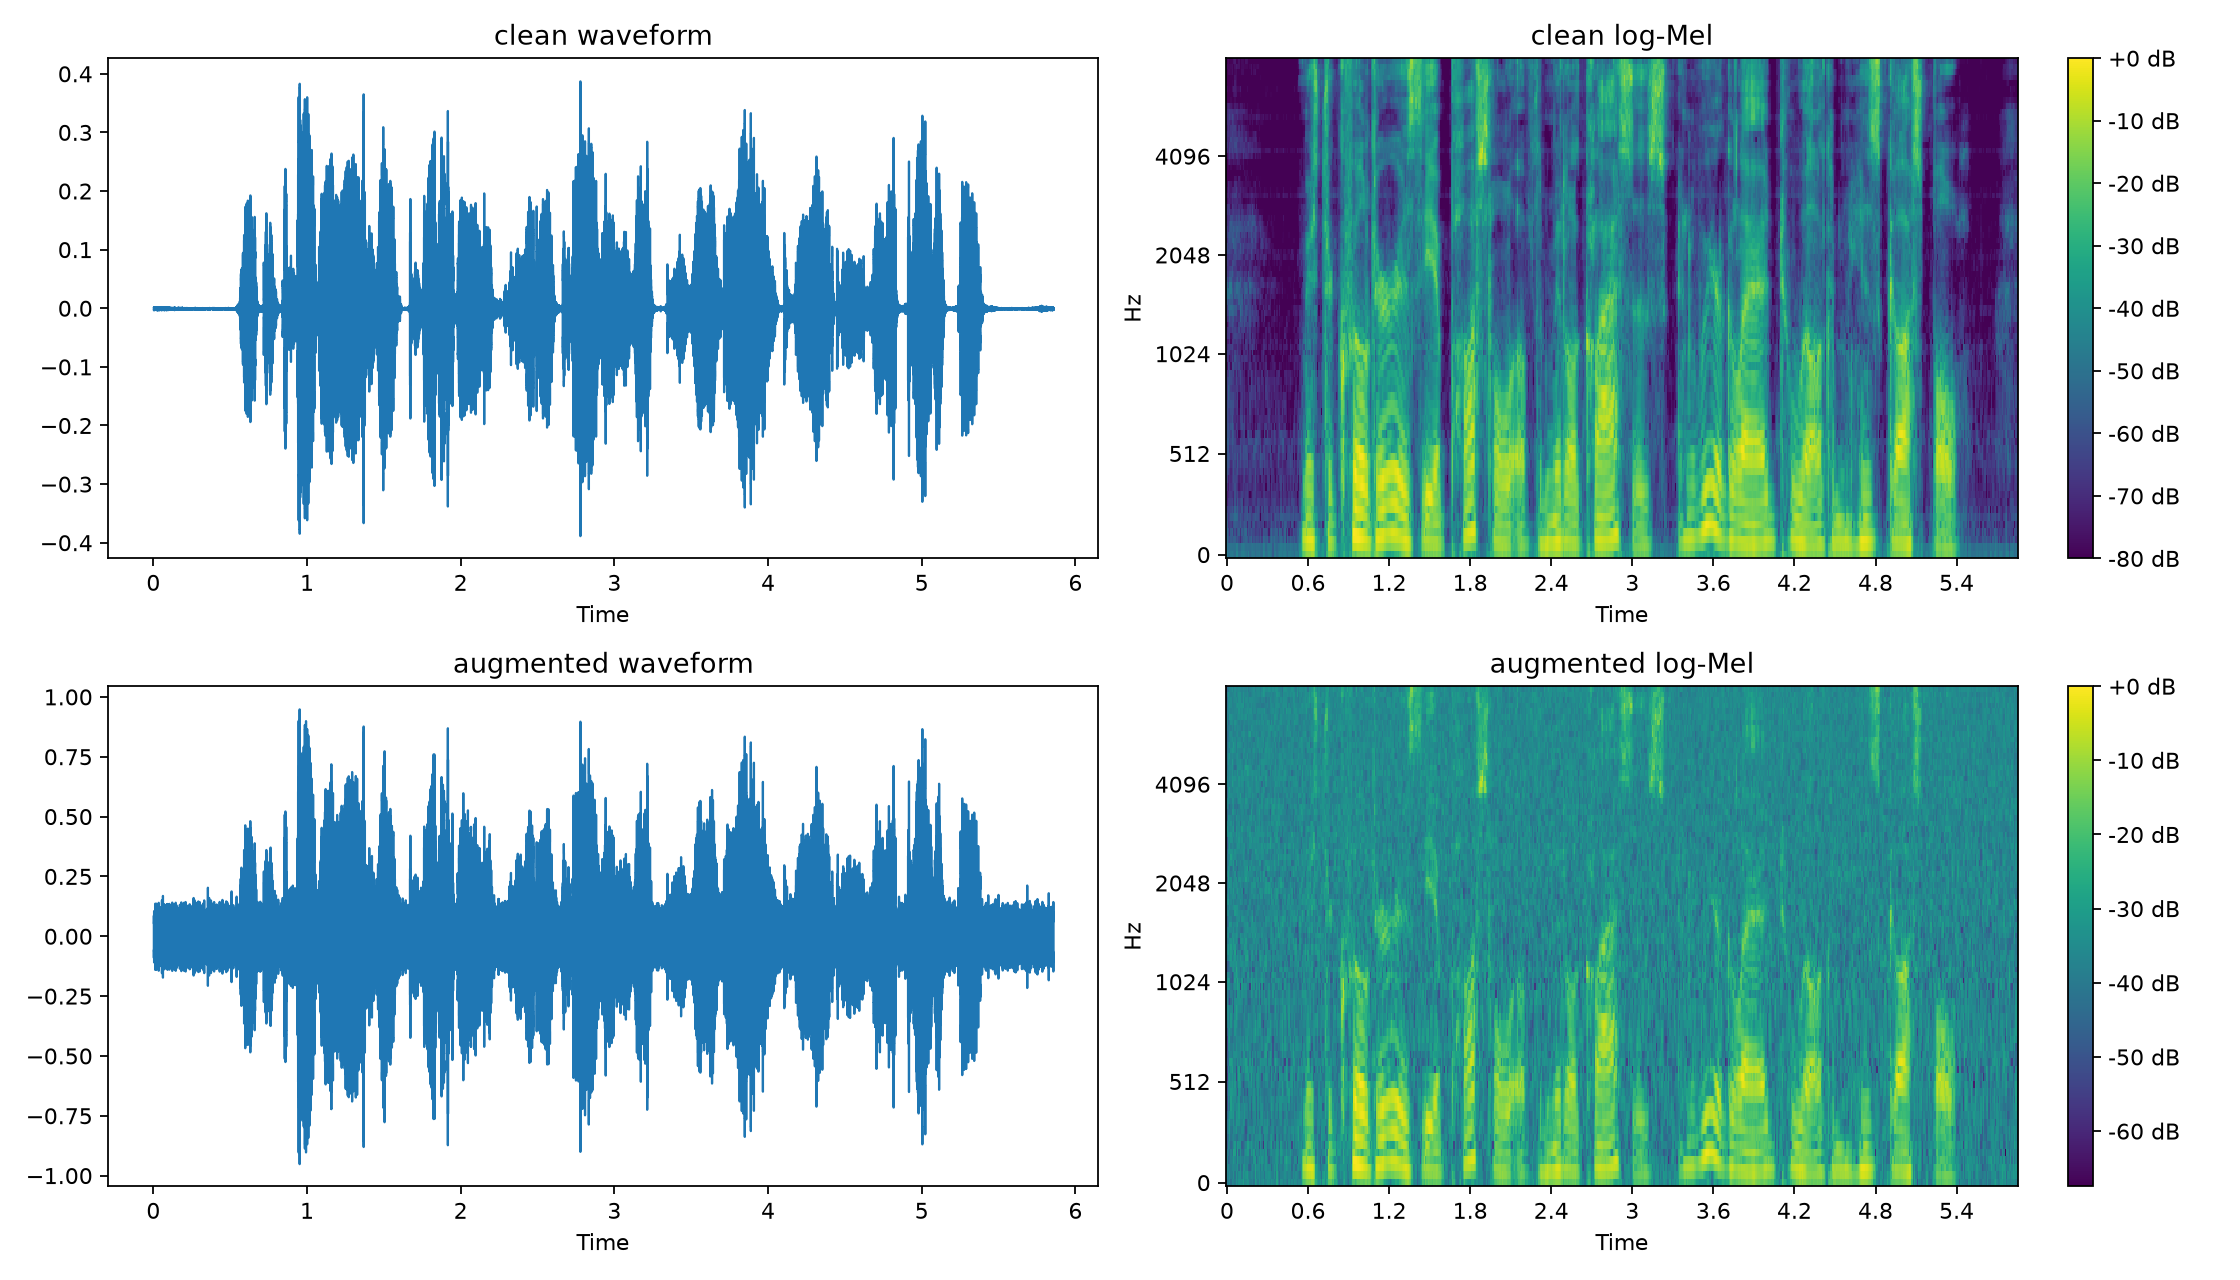

Теперь оригинал и реверберация room_a


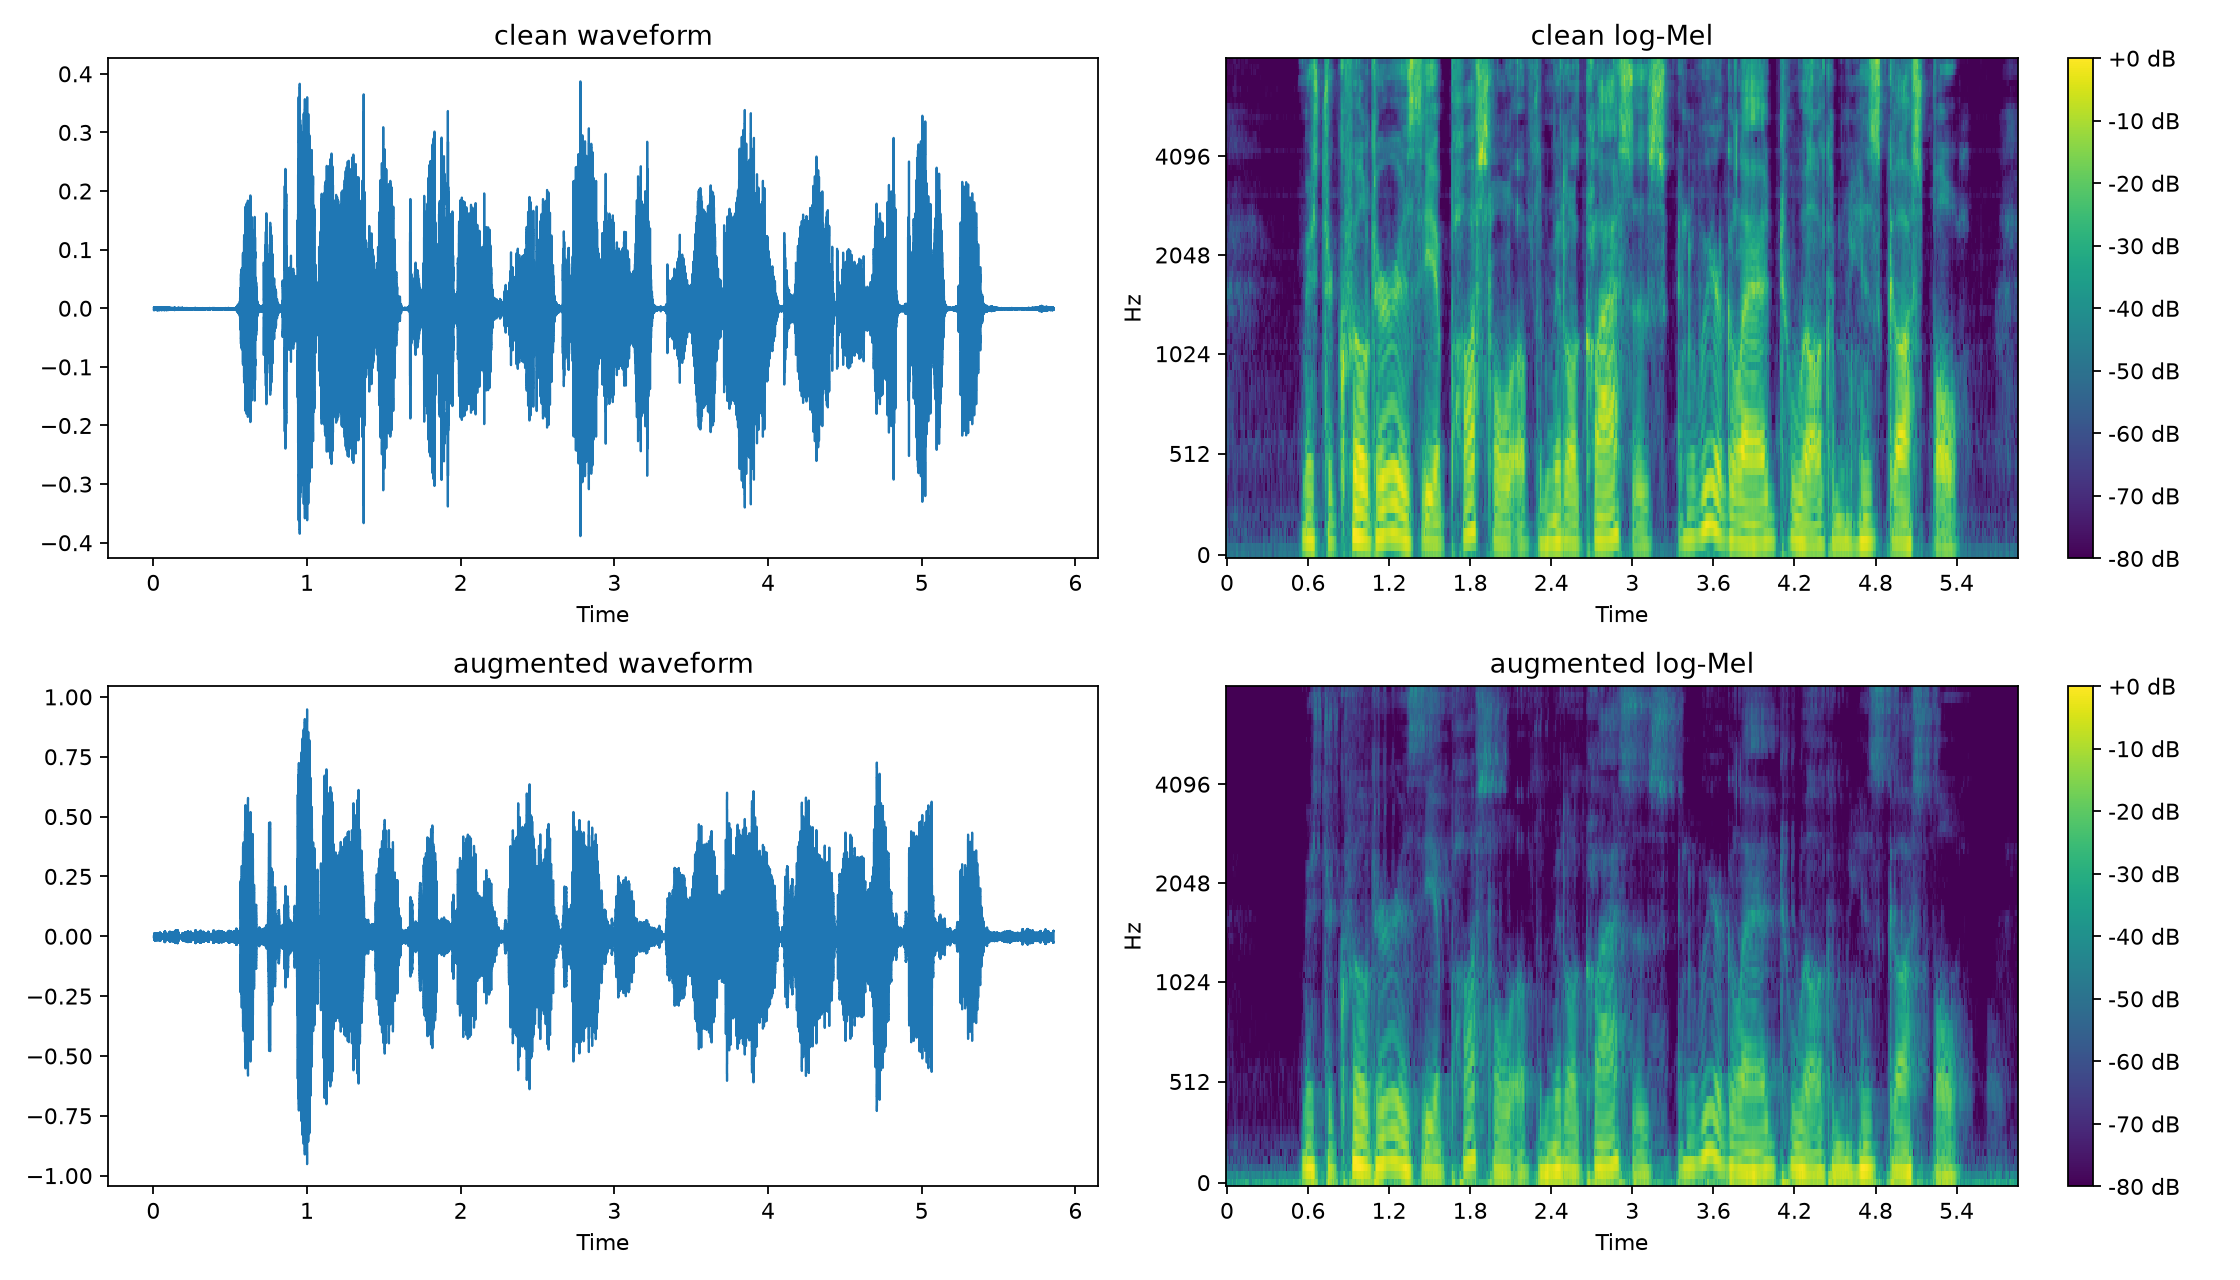

In [14]:
if FIG_READY:
    print("Сначала оригинал и шум 10 dB")
    display(Image(filename=str(FIG / "clean_vs_augmented.png"), width=900))

    print("Теперь оригинал и реверберация room_a")
    display(Image(filename=str(FIG / "reverb_room_a" / "clean_vs_augmented.png"), width=900))
else:
    print("Графики пока не построены.")

**Выводы**

1. **При шуме паузы перестают быть почти ровными.** На waveform в начале, в конце и между активными участками появляются колебания. На log-Mel тёмные области заполняются широкополосным фоном, особенно заметным там, где в clean было мало энергии. Т.е. шум добавляется и во время речи, и между словами
2. **При реверберации меняются затухания и контраст переходов.** На log-Mel часть следов звуков продолжается вправо, а границы становятся менее резкими. При этом не появляется такой же сплошной широкополосный фон, как от белого шума

Шум похож на шипение поверх разговора, а реверберация - на разговор в пустой комнате, где предыдущий звук ещё "тянется", когда уже начался следующий

**По высоте пиков напрямую сравнивать эти рисунки нельзя**: шкалы амплитуды разные, а искажённые записи нормализованы по пику. В log-Mel тоже используется отсчёт относительно максимума каждого сигнала. Поэтому сравниваю форму и расположение энергии, а не просто яркость или высоту графика

Звучание фразы в трёх вариантах

In [15]:
if AUG_READY:
    for condition in ["clean", "noise_10db", "reverb_room_a"]:
        path = AUG / (IDS[0] + "__" + condition + ".wav")
        if path.exists():
            print("Прослушивание:	", condition)
            display(Audio(filename=str(path)))
else:
    print("Аудиофайлы для прослушивания ещё не готовы.")

Прослушивание:	 clean


Прослушивание:	 noise_10db


Прослушивание:	 reverb_room_a


## Задание 2. Сравните аугментацию реверберацией room_a с аугментацией шумом (snr выберете сами). Какое видимое различие согласуется с временным размыванием, а не с простым аддитивным маскированием?

**Шум добавляет к речи другой сигнал.** $y(t)=x(t)+n(t)$: исходная речь плюс помеха. Тихая согласная может потеряться на фоне шипения, хотя время её произнесения не менялось. Это и есть акустическое маскирование - полезный звук становится труднее различить из-за другого звука.

**Реверберация складывает речь с её задержанными и ослабленными копиями.** В коде это свёртка с RIR - импульсным откликом помещения. RIR представляю как описание того, какие "отголоски" оставит в комнате один короткий хлопок

В предоставленном скрипте `augment_audio.py`, в функции `make_synthetic_rir`, для `room_a` заданы отражения с задержками **0.031, 0.079 и 0.143 с**, т.е. **31, 79 и 143 мс**

Сначала код создаёт затухающий отклик через `np.exp(-decay * time)`, а затем добавляет к нему отражения в указанные моменты. Поэтому в обработке участвуют не только три отдельных отражения, но и затухание между ними

| Что сравниваю | `noise_10db` | `reverb_room_a` |
|---|---|---|
| Откуда появилась дополнительная составляющая сигнала | Из добавленного случайного шума | Из задержанных частей самой речи |
| Что видно в паузах | Фоновое шипение | Послезвучие предыдущего события |
| Что происходит с переходами | Они маскируются фоном | Они дополнительно растягиваются во времени |

**Вывод:** с временным размыванием согласуются именно затухающие следы после речевых событий. Это похоже на смазанную фотографию: детали были в одном месте, а теперь их след тянется дальше




## Задание 3. Сравните длительности аудио 0.9× и 1.1× с исходыми. Как каждый фактор влияет на длительность и почему одного изменения длительности недостаточно для предсказания как себя поведёт WER?


Для изменения скорости используется ресемплинг - пересчёт числа отсчётов. После него WAV по-прежнему записывается с частотой 16 кГц:

$$T_{\text{новая}}\approx\frac{T_{\text{исходная}}}{k}$$

При `0.9x` длительность увеличится примерно на **11.11%**, при `1.1x` уменьшится примерно на **9.09%**. Это не симметричные ±10% по времени, т.к. мы делим на коэффициент скорости

Например, десятисекундная фраза займёт примерно 11.11 с при `0.9x` и 9.09 с при `1.1x`\
Проверю это на самих WAV, а затем отдельно сравню WER


In [26]:
if AUG_READY:
    rows = []

    for item_id in IDS:
        clean = sf.info(AUG / (item_id + "__clean.wav")).duration
        slow = sf.info(AUG / (item_id + "__speed_0.9x.wav")).duration
        fast = sf.info(AUG / (item_id + "__speed_1.1x.wav")).duration

        rows.append({
            "Запись": item_id,
            "clean, с": clean,
            "0.9x, с": slow,
            "1.1x, с": fast,
            "0.9x, %": (slow / clean - 1) * 100,
            "1.1x, %": (fast / clean - 1) * 100
        })

    df_duration = pd.DataFrame(rows)

    display(df_duration.style.format({
        "clean, с": "{:.3f}",
        "0.9x, с": "{:.3f}",
        "1.1x, с": "{:.3f}",
        "0.9x, %": "{:+.2f}%",
        "1.1x, %": "{:+.2f}%"
    }))
else:
    print("Пока нет записей, чтобы измерить длительности.")

,Запись,"clean, с","0.9x, с","1.1x, с","0.9x, %","1.1x, %"
0,1272-128104-0000,5.855,6.506,5.323,+11.11%,-9.09%
1,1272-128104-0001,4.815,5.350,4.377,+11.11%,-9.09%
2,1272-128104-0003,9.900,11.000,9.000,+11.11%,-9.09%
3,1272-128104-0006,5.640,6.267,5.127,+11.11%,-9.09%
4,1272-128104-0007,9.240,10.267,8.400,+11.11%,-9.09%


In [ ]:
if ASR_READY:
    conditions = ["clean", "speed_0.9x", "speed_1.1x"]

    df = item_rows[item_rows["condition"].isin(conditions)]

    # Переносим условия в отдельные столбцы
    df_wer = df.pivot(index="item_id", columns="condition", values="wer")

    df_wer = df_wer[conditions].copy()

    # Считаем процентное изменение относительно clean
    df_wer["0.9x, %"] = (df_wer["speed_0.9x"] / df_wer["clean"] - 1) * 100
    df_wer["1.1x, %"] = (df_wer["speed_1.1x"] / df_wer["clean"] - 1) * 100

    # Переименовываем столбцы
    df_wer = df_wer.rename(columns={
        "clean": "clean, WER",
        "speed_0.9x": "0.9x, WER",
        "speed_1.1x": "1.1x, WER"
    })

    display(df_wer.style.format({
        "clean, WER": "{:.6f}",
        "0.9x, WER": "{:.6f}",
        "1.1x, WER": "{:.6f}",
        "0.9x, %": "{:+.2f}%",
        "1.1x, %": "{:+.2f}%"
    }, na_rep="-"))

else:
    print("Для сравнения WER нужны результаты распознавания")

condition,"clean, WER","0.9x, WER","1.1x, WER","0.9x, %","1.1x, %"
item_id,,,,,
1272-128104-0000,0.058824,0.058824,0.058824,+0.00%,+0.00%
1272-128104-0001,0.100000,0.100000,0.100000,+0.00%,+0.00%
1272-128104-0003,0.041667,0.041667,0.041667,+0.00%,+0.00%
1272-128104-0006,0.166667,0.166667,0.083333,+0.00%,-50.00%
1272-128104-0007,0.052632,0.052632,0.052632,+0.00%,+0.00%


**Выводы по изменению скорости**

1. **Длительности совпали с ожиданием.** Первая запись изменилась с 5.855 с до 6.506 с при `0.9x` и до 5.323 с при `1.1x`. В остальных строках те же относительные изменения: +11.11% и −9.09%
2. **Замедление не изменило WER ни для одной из пяти фраз.** Средний WER у `clean` и `speed_0.9x` одинаковый: **0.083958**. При этом CER немного уменьшился: с 0.049979 до 0.047959. Одинаковое число словесных ошибок ещё не означает полностью одинаковый текст
3. **При ускорении средний WER уменьшился до 0.067291**, но улучшение связано только с записью `1272-128104-0006`: её WER снизился с 0.166667 до 0.083333. В остальных четырёх фразах WER не изменился. В этой записи `mr krilter` превратилось в `mr quilter`: одна замена фамилии исчезла, а сокращение `mr` осталось

Одной длительности недостаточно для предсказания WER. Здесь одновременно меняются **темп и высота звука**: при замедлении голос ниже, при ускорении выше

Модель должна распознать конкретные звуки и выбрать слова с учётом контекста. Поэтому результат зависит от того, какая фраза звучит и какие ошибки были у модели изначально.\
По одной улучшившейся фразе нельзя вывести сделать правило, что ускорение всегда полезно



## Задание 4. Какие области скрыты временными и частотными масками в specaugment_feature_only.png? Предположите, почему такая аугментация может быть полезной для обучения систем ASR?


SpecAugment меняет **признаки**, т.е. готовую log-Mel-матрицу, а не создаёт ещё один зашумлённый WAV. В ней 80 Mel-полос и 586 временных кадров



Размер спектрограммы:	 (80, 586)

Временная маска:	281–304 кадров
Интервал времени:	2.810–3.050 с

Частотная маска:	35–44 Mel-полос
Центры скрытых полос:	1404.8–1969.1 Гц
Область опоры фильтров:	1353.1–2044.4 Гц
Это полосы перекрывающихся фильтров, а не резкое удаление частот из WAV.

Спектрограмма до и после маскирования:


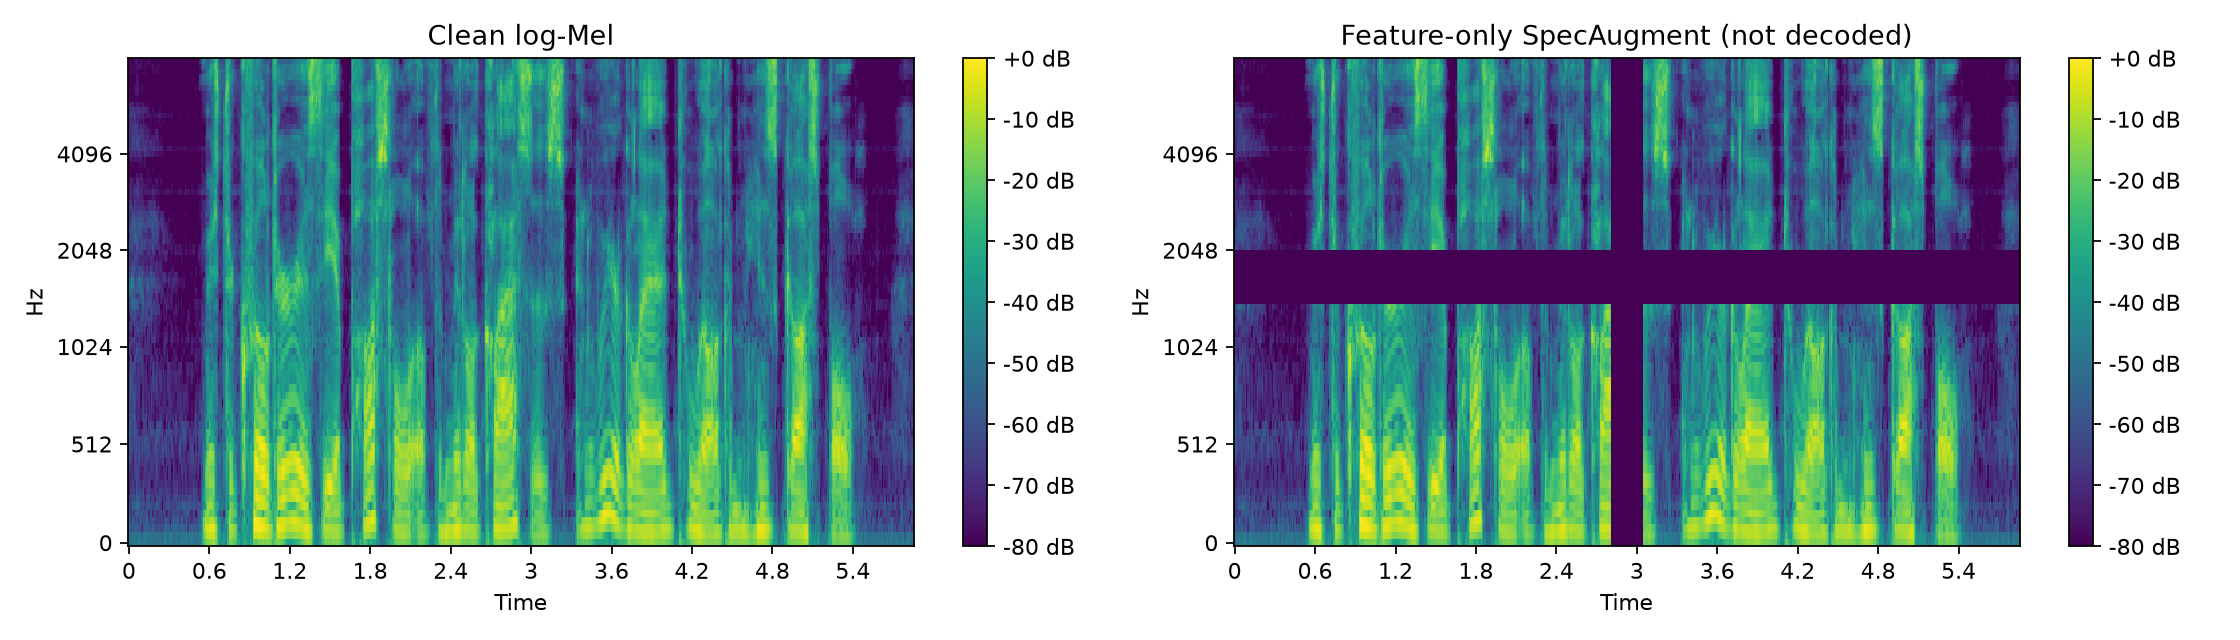

In [ ]:
if FIG_READY:
    import librosa
    sys.path.append(str(SCRIPTS.resolve()))
    from plot_augmentation_features import log_mel, specaugment

    audio, sr = librosa.load(WAV / (IDS[0] + ".wav"), sr=16000)

    mel = log_mel(audio, sr)
    masked, meta = specaugment(mel)

    print("Размер спектрограммы:\t", mel.shape)

    # Временная маска
    time_start = meta["time_start"]
    time_width = meta["time_width"]

    hop_length = 160
    time_from = time_start * hop_length / sr
    time_to = (time_start + time_width) * hop_length / sr

    print(f"\nВременная маска:\t{time_start}-{time_start + time_width - 1} кадров")
    print(f"Интервал времени:\t{time_from:.3f}-{time_to:.3f} с")

    # Частотная маска
    freq_start = meta["frequency_start"]
    freq_width = meta["frequency_width"]
    freq_end = freq_start + freq_width - 1

    # У 80 треугольных Mel-фильтров 82 опорные частоты.
    # Полоса i: левая граница i, центр i+1, правая граница i+2.
    mel_points = librosa.mel_frequencies(
        n_mels=mel.shape[0] + 2, fmin=20, fmax=7600
    )

    print(f"\nЧастотная маска:\t{freq_start}-{freq_end} Mel-полос")
    print(f"Центры скрытых полос:\t{mel_points[freq_start + 1]:.1f}-"
          f"{mel_points[freq_end + 1]:.1f} Гц")
    print(f"Область опоры фильтров:\t{mel_points[freq_start]:.1f}-"
          f"{mel_points[freq_end + 2]:.1f} Гц")
    print("Это полосы перекрывающихся фильтров, а не резкое удаление частот из WAV.")

    print("\nСпектрограмма до и после маскирования:")
    display(Image(filename=str(FIG / "specaugment_feature_only.png"), width=900))
else:
    print("Рисунок SpecAugment пока отсутствует.")

1. **Временная маска** закрывает кадры 281-304 включительно, всего 24 кадра. Шаг кадра равен 160 / 16000 = 0.01 с => ширина маски на временной сетке около **0.24 с**, интервал `[2.81; 3.05)` с. Это вертикальная полоса через все частоты
2. **Частотная маска** закрывает Mel-полосы 35-44 включительно, всего 10 из 80, на всей длине записи. Это горизонтальная полоса. У Mel-фильтров есть ширина и перекрытие, поэтому номер полосы нельзя считать одной точной частотой в герцах
3. **Значения заменяются минимумом матрицы**, а не числом 0

Это как текст, где часть букв закрыли бумажкой: приходится пользоваться оставшимся контекстом.\
При обучении похожий приём может уменьшить зависимость от одного короткого звука или частотной области.\
Это регуляризация - модель меньше привязывается к отдельным деталям обучающих примеров

## Задание 5. Для одного тестового примера сравните результаты распознавания чистого сигнала с результатами двух его аугментированных вариантов. Укажите WER, CER и RTF для всех трёх аудио. Какая метрика изменяется сильнее всего в выбранном сравнении? Как думаете, почему?


Для сравнения выбрал запись `1272-128104-0000` в условиях **`clean`, `noise_0db`, `reverb_room_a`**. Здесь специально беру сильный шум, чтобы отличие от исходного результата было заметнее

Смотрю и на тексты, и на три метрики. Одно число не показывает, какое именно слово потерялось: одинаковый WER может получиться при разных ошибках. RTF рассматриваю отдельно


In [ ]:
if ASR_READY:
    conditions = ["clean", "noise_0db", "reverb_room_a"]

    # Выбираем первую запись и три условия
    selected = item_rows[
        (item_rows["item_id"] == IDS[0]) &
        (item_rows["condition"].isin(conditions))
    ].copy()

    selected = selected.set_index("condition").loc[conditions]

    # Эталонные и распознанные тексты
    print("Сравнение эталонных и распознанных текстов:")

    display(selected[[
        "reference_normalized",
        "hypothesis_normalized"
    ]].style.set_properties(**{
        "text-align": "left",
        "white-space": "normal"
    }))

    print("\nСравнение метрик распознавания:")

    display(selected[
        ["wer", "cer", "rtf"]
    ].style.format("{:.6f}"))
else:
    print("Нужны результаты Whisper, чтобы заполнить сравнение.")

Сравнение эталонных и распознанных текстов:


,reference_normalized,hypothesis_normalized
condition,,
clean,mister quilter is the apostle of the middle classes and we are glad to welcome his gospel,mr quilter is the apostle of the middle classes and we are glad to welcome his gospel
noise_0db,mister quilter is the apostle of the middle classes and we are glad to welcome his gospel,if the closure is the apostle of the middle classes i'm glad you are in this gospel
reverb_room_a,mister quilter is the apostle of the middle classes and we are glad to welcome his gospel,mr quilter is the apostle of the middle classes and we are glad to welcome his gospel



Сравнение метрик распознавания:


,wer,cer,rtf
condition,,,
clean,0.058824,0.044944,0.047170
noise_0db,0.588235,0.359551,0.047644
reverb_room_a,0.058824,0.044944,0.042163


**Выводы по одной записи**

1. **Чистая запись уже не даёт нулевую ошибку.** В эталоне написано `mister`, а в гипотезе `mr`. По смыслу это сокращение того же обращения, но нормализатор его не раскрывает => одна замена на 17 слов и WER = 0.058824
2. **При `noise_0db` WER вырос примерно в 10 раз, CER - в 8 раз.** В процентных пунктах это +52.94 для WER и +31.46 для CER. При сильном шуме изменилось уже несколько фрагментов: `mister quilter` -> `if the closure`, а часть `and we are glad to welcome his` распознана как `i'm glad you are in this`. Это больше, чем выбор сокращения
3. **При реверберации нормализованный текст в этой фразе совпал с clean.** Модель справилась с изменением без дополнительных ошибок. Это не означает, что реверберация безвредна для остальных записей: ниже сравниваю средние значения по всем пяти фразам
4. **RTF во всех трёх случаях меньше 1.** Для clean обработка 5.855 с аудио заняла примерно 0.276 с. При шуме текст сильно ухудшился, а RTF изменился мало. Т.е. быстрое распознавание может оказаться неточным

**Сильнее всего по относительному росту изменилась WER.** Предполагаю, что шум скрыл часть речевых деталей, и модель выбрала другие слова. При этом внутри неправильных слов часть букв всё ещё совпадает => CER вырос меньше. По текстам видно ухудшение




## Задание 6. Определите вариант аугментации с наибольшим агрегированным mean_wer в aggregate_results.csv. Укажите его имя, агрегированные mean_wer, mean_cer и сравнение текстовок для одного тестового примера с этой аугментацией. Как вы думаете, почему такая аугментация сильнее всего сказывается на работе ASR модели?


Теперь сравню средний WER по всем пяти фразам\
Ищу максимум `mean_wer` среди искажённых вариантов, затем смотрю пример с самым большим WER внутри этого условия

In [80]:
if ASR_READY:
    # Находим аугментацию с самым большим средним WER
    df = agg_rows[agg_rows["condition"] != "clean"]
    worst = df.loc[df["mean_wer"].idxmax()]

    print("Самая сложная аугментация:\t", worst["condition"])
    print("mean_wer:\t", worst["mean_wer"])
    print("mean_cer:\t", worst["mean_cer"])

    # Выбираем запись с самым большим WER для этой аугментации
    df = item_rows[item_rows["condition"] == worst["condition"]]
    example = df.loc[df["wer"].idxmax()]

    print("\nID записи:\t", example["item_id"])
    print("Эталон:\t", example["reference_raw"])
    print("Распознавание:\t", example["hypothesis_raw"])

    # Предполагаем причину ухудшения распознавания
    if worst["condition"].startswith("noise"):
        print("\nПредположение:\tдобавленный шум скрывает важные части речи.")
    elif worst["condition"].startswith("reverb"):
        print("\nПредположение:\tотражения размывают границы звуков и слов.")
    else:
        print("\nПредположение:\tизменение темпа и высоты звука мешает модели.")
else:
    print("Определить максимальный mean_wer можно только по готовому CSV.")

Самая сложная аугментация:	 noise_0db
mean_wer:	 0.700015
mean_cer:	 0.390167

ID записи:	 1272-128104-0006
Эталон:	 ON THE GENERAL PRINCIPLES OF ART MISTER QUILTER WRITES WITH EQUAL LUCIDITY
Распознавание:	 And the general principles of art in the future of the rights for people in this city.

Предположение:	добавленный шум скрывает важные части речи.


**Выводы по самой сложной аугментации**

1. **Наибольший средний WER у `noise_0db`: 0.700015**, средний CER = **0.390167**. Для `clean` это 0.083958 и 0.049979. Получается рост WER примерно в **8.34 раза**, CER - в **7.81 раза**
2. В примере `1272-128104-0006` эталон содержит `mister quilter writes with equal lucidity`, а модель выдала `in the future of the rights for people in this city`. Т.е. неправильно распознано уже несколько соседних слов, а не только фамилия
3. При SNR = 0 dB средняя мощность добавленного шума равна средней мощности речи по записи. Это не означает, что каждый звук полностью исчез: громкие и тихие участки всё ещё различаются. Но слабые речевые детали становится труднее отделить от фона

Если в разговоре плохо слышно окончания и согласные, можно угадать знакомое слово по контексту, но можно и собрать совсем другую фразу. Похоже, здесь модель тоже частично опирается на контекст, когда аудио стало менее разборчивым

По среднему WER видна последовательность: **0.120625 при 20 dB -> 0.182291 при 10 dB -> 0.700015 при 0 dB**. В этом запуске более сильный шум сопровождался большим числом ошибок

**Вывод:** `noise_0db` оказалось самым сложным условием для `tiny.en` на этих пяти фразах



## Задание 7. Найдите такой тип аугментации, для которого WER и CER сигнализируют о разном уровне влияния на систему ASR (скажем WER деградирует значительно, но CER увеличивается не очень сильно). Рассмотрите текстовки, предположите, почему наблюдается такое поведение?.


WER считает неправильным всё слово, даже если изменилась только одна буква. CER показывает, сколько изменений нужно на уровне символов. 

Чтобы сравнение было понятнее, ниже делю средние метрики каждого условия на соответствующие значения clean. Так видно **рост каждой метрики относительно её собственной базы**, а не просто то, что WER численно больше CER

В столбце `difference` считается отношение этих коэффициентов роста


In [77]:
if ASR_READY:
    # Сравниваем средние метрики с clean
    clean = agg_rows[agg_rows["condition"] == "clean"].iloc[0]

    df = agg_rows[agg_rows["condition"] != "clean"].copy()

    df["wer_growth"] = df["mean_wer"] / clean["mean_wer"]
    df["cer_growth"] = df["mean_cer"] / clean["mean_cer"]

    # Сравниваем относительный рост метрик
    df["difference"] = df["wer_growth"] / df["cer_growth"]

    columns = ["mean_wer", "mean_cer", "wer_growth", "cer_growth", "difference"]

    display(df[["condition"] + columns].style.format("{:.3f}", subset=columns))

    # Ищем аугментацию, где WER растёт сильнее CER
    df = df[(df["wer_growth"] > 1) & (df["difference"] > 1)]

    if not df.empty:
        worst = df.loc[df["difference"].idxmax()]

        print("\nАугментация:\t", worst["condition"])
        print(f"Рост WER:\t{worst['wer_growth']:.3f} раза")
        print(f"Рост CER:\t{worst['cer_growth']:.3f} раза")

        # Выбираем запись с самым большим расхождением
        clean_items = item_rows[item_rows["condition"] == "clean"][
            ["item_id", "wer", "cer"]
        ]

        examples = item_rows[
            item_rows["condition"] == worst["condition"]
        ].merge(clean_items, on="item_id", suffixes=("", "_clean"))

        examples["difference"] = (
            (examples["wer"] - examples["wer_clean"]) -
            (examples["cer"] - examples["cer_clean"])
        )

        example = examples.loc[examples["difference"].idxmax()]

        print("\nЗапись:\t", example["item_id"])
        print("Эталон:\t", example["reference_raw"])
        print("Гипотеза:\t", example["hypothesis_raw"])

else:
    print("Для сравнения нужны результаты распознавания.")

,condition,mean_wer,mean_cer,wer_growth,cer_growth,difference
1,noise_0db,0.700,0.390,8.338,7.807,1.068
2,noise_10db,0.182,0.100,2.171,2.003,1.084
3,noise_20db,0.121,0.073,1.437,1.461,0.983
4,reverb_room_a,0.121,0.061,1.437,1.217,1.180
5,speed_0.9x,0.084,0.048,1.000,0.960,1.042
6,speed_1.1x,0.067,0.045,0.801,0.892,0.899



Аугментация:	 reverb_room_a
Рост WER:	1.437 раза
Рост CER:	1.217 раза

Запись:	 1272-128104-0001
Эталон:	 NOR IS MISTER QUILTER'S MANNER LESS INTERESTING THAN HIS MATTER
Гипотеза:	 Nor is Mr. Quilter's matter less interesting than his matter.


**Выводы по расхождению WER и CER**

1. **По выбранному отношению коэффициентов роста выделяется `reverb_room_a`.** WER увеличился с 0.083958 до 0.120625, т.е. на **43.7%**. CER вырос с 0.049979 до 0.060840 - **21.7%*
2. В записи `1272-128104-0001` эталон содержит `mister quilter's manner`, а при реверберации получилось `mr quilter's matter`. Сокращение `mister` -> `mr` было и у clean. Дополнительное отличие здесь - **`manner` -> `matter`**
3. В `manner` и `matter` меняются две буквы из шести. Для WER это одна ошибка целого слова, а для CER - две замены символов в строке, большая часть которой осталась правильной. Поэтому WER и CER дают разный масштаб ухудшения

Предполагаю, что отражённые части речи наложились на соседние звуки и модели стало сложнее различить похожие слова. Но сами метрики не доказывают, какая фонема была замаскирована и были ли ошибки границ слов: они только сравнивают получившиеся тексты

`reverb_room_a` выделяется по отношению относительных ростов, а самые большие значения самих ошибок остаются у `noise_0db`

Высокий WER ещё не обязательно означает, что модель "потеряла" всю фразу. Иногда она заменила несколько похожих слов, сохранив большую часть букв и предложения. Поэтому рядом с метриками нужно читать сами гипотезы


## Задание 8. Для идентичной ошибки/ошибок распознавания при разных типах аугментации приведите эталон и гипотезу (или их фрагменты). Является ли правдоподобным объяснением акустическое маскирование, временное размывание, сегментация/тайминг или предпочтение декодера/языковой модели? Укажите, какие у вас есть предположения, относительно таких ошибок распознавания.


Найду фрагменты, которые одинаково отличаются от эталона при нескольких аугментациях. Для этого использую `difflib`: он помогает выделить разные группы слов, чтобы не искать их во всех строках вручную

**Это вспомогательная разметка, а не расчёт WER**

В таблице ниже сравниваются только искажённые варианты


In [ ]:
import difflib

if ASR_READY:
    errors = []

    print("Контрольный пример: ошибка в clean и изменённых записях")
    context = item_rows[
        (item_rows["item_id"] == "1272-128104-0003") &
        item_rows["condition"].isin([
            "clean", "reverb_room_a", "speed_0.9x", "speed_1.1x"
        ])
    ]
    display(context[[
        "condition", "reference_normalized", "hypothesis_normalized", "wer"
    ]].style.set_properties(**{
        "text-align": "left", "white-space": "normal"
    }))

    # Сравниваем все записи при всех аугментациях
    df = item_rows[item_rows["condition"] != "clean"]

    for _, row in df.iterrows():
        correct_words = row["reference_normalized"].split()
        guess_words = row["hypothesis_normalized"].split()

        compare = difflib.SequenceMatcher(None, correct_words, guess_words)

        for kind, a, b, c, d in compare.get_opcodes():
            if kind == "equal":
                continue

            errors.append({
                "item_id": row["item_id"],
                "condition": row["condition"],
                "Тип ошибки": kind,
                "Эталонный фрагмент": " ".join(correct_words[a:b]),
                "Распознанный фрагмент": " ".join(guess_words[c:d])
            })

    # Создаём таблицу всех ошибок
    df_errors = pd.DataFrame(errors)

    if not df_errors.empty:
        print("Все найденные ошибки распознавания:\n")
        display(df_errors)

        # Ищем одинаковые ошибки при разных аугментациях
        repeated = df_errors.groupby([
            "item_id",
            "Эталонный фрагмент",
            "Распознанный фрагмент"
        ]).agg({
            "condition": lambda x: ", ".join(sorted(set(x))),
            "Тип ошибки": "first"
        }).reset_index()

        repeated["Количество условий"] = repeated["condition"].apply(
            lambda x: len(x.split(", "))
        )

        repeated = repeated[repeated["Количество условий"] >= 2]

        print("\nОшибки, повторяющиеся при разных аугментациях:\n")

        if not repeated.empty:
            display(repeated)
        else:
            print("Повторяющихся ошибок не найдено.")

    else:
        print("Ошибок распознавания не найдено.")
else:
    print("Чтобы сравнить тексты, нужны результаты ASR.")

Контрольный пример: ошибка в clean и изменённых записях
Все найденные ошибки распознавания:


Ошибки, повторяющиеся при разных аугментациях:



,condition,reference_normalized,hypothesis_normalized,wer
14,clean,he has grave doubts whether sir frederick leighton's work is really greek after all and can discover in it but little of rocky ithaca,he has grave doubts whether sir frederick layton's work is really greek after all and can discover in it but little of rocky ithaca,0.041667
18,reverb_room_a,he has grave doubts whether sir frederick leighton's work is really greek after all and can discover in it but little of rocky ithaca,he has grave doubts whether sir frederick layton's work is really greek after all and can discover in it but little of wonky ithaka,0.125000
19,speed_0.9x,he has grave doubts whether sir frederick leighton's work is really greek after all and can discover in it but little of rocky ithaca,he has grave doubts whether sir frederick layton's work is really greek after all and can discover in it but little of rocky ithaca,0.041667
20,speed_1.1x,he has grave doubts whether sir frederick leighton's work is really greek after all and can discover in it but little of rocky ithaca,he has grave doubts whether sir frederick layton's work is really greek after all and can discover in it but little of rocky ithaca,0.041667


,item_id,condition,Тип ошибки,Эталонный фрагмент,Распознанный фрагмент
0,1272-128104-0000,noise_20db,replace,mister,mr
1,1272-128104-0000,noise_10db,replace,mister,mr
2,1272-128104-0000,noise_0db,replace,mister quilter,if the closure
3,1272-128104-0000,noise_0db,replace,and we,i'm glad you
4,1272-128104-0000,noise_0db,replace,glad to welcome his,in this
5,1272-128104-0000,reverb_room_a,replace,mister,mr
6,1272-128104-0000,speed_0.9x,replace,mister,mr
7,1272-128104-0000,speed_1.1x,replace,mister,mr
8,1272-128104-0001,noise_20db,replace,mister quilter's,mr colter's
9,1272-128104-0001,noise_10db,replace,mister quilter's manner,mr colter's matter


,item_id,Эталонный фрагмент,Распознанный фрагмент,condition,Тип ошибки,Количество условий
2,1272-128104-0000,mister,mr,"noise_10db, noise_20db, reverb_room_a, speed_0...",replace,5
4,1272-128104-0001,manner,matter,"noise_0db, reverb_room_a",replace,2
5,1272-128104-0001,mister,mr,"noise_0db, reverb_room_a, speed_0.9x, speed_1.1x",replace,4
11,1272-128104-0003,grave,great,"noise_10db, noise_20db",replace,2
14,1272-128104-0003,leighton's,layton's,"noise_20db, reverb_room_a, speed_0.9x, speed_1.1x",replace,4
21,1272-128104-0006,mister quilter,mr krilter,"noise_10db, noise_20db, reverb_room_a, speed_0.9x",replace,4
27,1272-128104-0007,fact,effect,"noise_10db, noise_20db, reverb_room_a, speed_1.1x",replace,4


**Выводы по повторяющимся ошибкам**

1. **`leighton's` -> `layton's` в записи `1272-128104-0003`.** В исходной clean-гипотезе тоже есть `layton's`. Поэтому специально добавленный шум или реверберация не нужны для появления этой ошибки
2. **`mister` -> `mr` встречается в нескольких условиях.** Слово передано сокращением, но нормализатор сравнивает их как разные строки. Смысл не изменился, а WER всё равно учитывает замену. Это пример зависимости оценки от правил оформления текста
3. **`manner` -> `matter` повторяется при сильном шуме и реверберации**, а `grave` -> `great` - при шуме 10 и 20 dB. Здесь совпадение результата ещё не означает совпадение причины: разные искажения могли сделать похожие звуки менее различимыми

Для примера с фамилией:

| Источник | Фрагмент |
|---|---|
| Эталон | `sir frederick leighton's work` |
| `clean` | `sir frederick layton's work` |
| `reverb_room_a` | `sir frederick layton's work` |
| `speed_0.9x` и `speed_1.1x` | `sir frederick layton's work` |

**Предположение:** похожее звучание фамилий допускает несколько написаний, а модель выбирает одно с учётом выученных языковых закономерностей.\
Это как фамилия, которую услышал впервые: звучание можно повторить, а правильное написание всё равно приходится уточнять

| Возможное объяснение | Что могу сказать по результатам |
|---|---|
| Акустическое маскирование | Правдоподобно для новых ошибок под шумом; повторение фамилии в clean им одним не объясняется |
| Временное размывание | Правдоподобно для дополнительных замен при реверберации, но не требуется для появления замены фамилии |
| Сегментация / тайминг | По одним текстам исключить нельзя; нужно отдельно изучать аудио и временные границы |
| Предпочтение декодера | Правдоподобно для написания фамилии и выбора `mr`, но напрямую в эксперименте не проверено |

**Главный вывод:** одинаковые ошибки при разных искажениях могут указывать на особенности самой модели и оформления текста. Для объяснения полезно сначала проверить, была ли эта ошибка уже в clean, а затем смотреть, что добавилось после аугментации


## Задание 9. Как вы думаете, всегда ли более высокий WER в нашем бенчмарке, есть индикатор того, что такая аугментация - универсальная ASR? Назовите два фактора в этой лабораторной работе, которые не позволяют сделать такой вывод.


**Нет.** Больший WER показывает, что конкретная модель хуже справилась с конкретными записями при заданных параметрах искажения. Для универсального вывода этого недостаточно

Два основных ограничения:
1. **Всего пять фраз одного диктора.** Здесь нет разнообразия голосов, темпов и манер речи. Даже средний результат заметно зависит от одной записи: при `speed_1.1x` улучшение WER получилось только на фразе `1272-128104-0006`, а у остальных четырёх WER остался прежним. При `speed_0.9x` WER не улучшился вообще. Т.е. по этому опыту нельзя сделать правило "изменение скорости помогает всем"
2. **Проверена только Whisper `tiny.en` с одними настройками.** Другая модель, другой режим вычислений или настройки декодирования могут изменить и сами ошибки, и порядок сложности условий

Кроме того, используется один набор искусственных искажений.

Для более общих выводов я бы взял больше фраз и дикторов, несколько моделей, разные шумы и помещения, а шумовые варианты повторил с несколькими seed. Тогда можно было бы проверить, сохраняется ли наблюдаемый порядок условий, и оценить разброс результатов.

**Итог работы**

- **Шум** добавляет фон и может скрывать слабые речевые детали. В сохранённом запуске хуже всего оказалось `noise_0db`: mean WER = **0.700015** против **0.083958** у clean
- **Реверберация** растягивает события по времени. На первой фразе дополнительных ошибок не появилось, но средний WER вырос до **0.120625** => одной удачной записи недостаточно для вывода обо всём условии
- **Изменение скорости** предсказуемо меняет длительность, а WER - не обязательно. При `0.9x` он остался прежним, при `1.1x` уменьшился за счёт одной фразы
- **WER и CER** показывают ошибки с разной подробностью. **RTF** показывает скорость, поэтому быстрый ответ ещё не означает правильный текст

Для себя связываю две ЛР так: сначала проверяю, **что изменилось в аудио и признаках**, затем читаю **что именно распознала модель**, и только после этого объясняю метрики. Иначе легко принять сокращение `mr` за потерю смысла или по одной удачной фразе решить, что аугментация всегда улучшает ASR
